This code generates Figure 5 for "Wasting is essential: cachexia is driven by a wound-healing adaptation" First, one wants to analyze the effect that nutritional support will have on healing in acute wound contexts, through examining the wound healing time and amino acid loss integrals. Then, one moves onto analyzing the cancer context by examining the effect of nutritional support on the steady state value of weight.

In [29]:
import numpy as np

import matplotlib.pyplot as plt

from reaction_flask import ReactionFlask

In [30]:
numPointsToTest = 20
inflammationGenerationParam = 8

In [31]:
initWound = 1

woundValsVsTime = []

acuteWoundSimulationOutputs = [[], [], []]

for j in range(3):

    if j in [0, 1]:
        diet = 1
    else:
        diet = 2


    rxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_A', 'L_phi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'A', 'phi', 'pI'], components = {"Liver" : ['L_N', 'L_A', 'L_phi'], "Muscle" : ['M_full'], "Soluble Mediators" : ['A', 'phi', 'pI'], "Wound" : ['W'], "Inputs" : ['D', 'D_phi']})

    rxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.5, 0, 100, 100, 0, 0, 1, 0, 0])

    rxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

    #
    rxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

    #
    rxnFlask.addReaction("Reaction 3: L_A + A -> L_N + A", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

    #
    rxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

    #
    rxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

    #
    rxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

    #
    rxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

    #
    rxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

    #
    rxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

    #
    rxnFlask.addReaction("Reaction 12: W -> W + phi", inflammationGenerationParam, reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

    #
    rxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

    #
    rxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

    #
    rxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

    #
    rxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

    #
    rxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

    #
    rxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

    #
    rxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


    #
    rxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

    #
    rxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



    #
    #This allows S_full to continue acting as an inflammation sink without changing state
    #rxnFlask.addReaction("Reaction 13a: S_full + g * phi -> S_phi", 1, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_phi' : 1})
    #rxnFlask.addReaction("Reaction 13b: S_full + g * phi -> S_full", 0, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_full' : 1})


    #This allows S_empty to continue acting as an inflammation sink without changing state
    #rxnFlask.addReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", 1, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_ePhi' : 1})
    #rxnFlask.addReaction("Reaction 14b: S_empty + g * phi -> S_empty", 0, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_empty' : 1})


    #This allows M_full to continue acting as an inflammation sink while not changing state
    rxnFlask.addReaction("Reaction 7: M_full + g * phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})
    rxnFlask.addReaction("Reaction 22: M_full + g * phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


    #This allows M_empty to continue acting as an inflammation sink while not changing state
    rxnFlask.addReaction("Reaction 8: M_empty + g * phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})
    rxnFlask.addReaction("Reaction 23: M_empty + g * phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})

    for k in range(numPointsToTest):

        R = (1 / (numPointsToTest - 1)) * k

        #rxnFlask.modifyReaction("Reaction 13a: S_full + g * phi -> S_phi", newRxnRate = R)
        #rxnFlask.modifyReaction("Reaction 13b: S_full + g * phi -> S_full", newRxnRate = 1 - R)


        #This allows S_empty to continue acting as an inflammation sink without changing state
        #rxnFlask.modifyReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", newRxnRate = R)
        #rxnFlask.modifyReaction("Reaction 14b: S_empty + g * phi -> S_empty", newRxnRate = 1 - R)


        #This allows M_full to continue acting as an inflammation sink while not changing state
        rxnFlask.modifyReaction("Reaction 7: M_full + g * phi -> M_phi" , newRxnRate = R)
        rxnFlask.modifyReaction("Reaction 22: M_full + g * phi -> M_full" , newRxnRate = 1 - R)


        #This allows M_empty to continue acting as an inflammation sink while not changing state
        rxnFlask.modifyReaction("Reaction 8: M_empty + g * phi -> M_ePhi" ,newRxnRate = R)
        rxnFlask.modifyReaction("Reaction 23: M_empty + g * phi -> M_empty", newRxnRate = 1 - R)

        if j == 0:
            #
            rxnFlask.modifyReaction("Reaction 20: D + phi -> D_phi + phi", newRxnRate= 1)

            #
            rxnFlask.modifyReaction("Reaction 21: D_phi -> D", newRxnRate= 0.1)
        else:
            #
            rxnFlask.modifyReaction("Reaction 20: D + phi -> D_phi + phi", newRxnRate= 0)
            
            #
            rxnFlask.modifyReaction("Reaction 21: D_phi -> D", newRxnRate= 0)

        #reactionDerivative1 = rxnFlask.reactionDeriv(0, [initWound, diet, 0, 0.334, 0.333, 0.333, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

        rxnFlask.runSystem(500)
        
        
        #rxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

        timeValues = rxnFlask.latestSimulationOutput["t"]

        localWeightDropValues = (46 * 2 - rxnFlask.latestSimulationOutput["y"][7] - rxnFlask.latestSimulationOutput["y"][11])

        print(np.max(localWeightDropValues) / (46 * 2))

        #print(rxnFlask.latestSimulationOutput["t"])

        print(f"Final value of W: {rxnFlask.getFinalValueOfSpecies('W')}")

        rxnFlask.resetInitialCondition()

        acuteWoundSimulationOutputs[j].append(rxnFlask.latestSimulationOutput)

-0.08695652173913043
Final value of W: 0.057660389892736544
-0.03216453656451889
Final value of W: 0.054018551194779815
0.04845369591649036
Final value of W: 0.05078179051863744
0.1242596523872888
Final value of W: 0.04789847564546197
0.193875222784989
Final value of W: 0.04532338765729306
0.2574327694103584
Final value of W: 0.043017163705554654
0.3153157118840151
Final value of W: 0.04094568019063808
0.36796206428925
Final value of W: 0.03907943234233233
0.41581329102660797
Final value of W: 0.037392944325402085
0.4592966738582491
Final value of W: 0.03586422839905564
0.4988181029108459
Final value of W: 0.03447430116760532
0.5347559991131873
Final value of W: 0.03320675830185675
0.567461345381521
Final value of W: 0.032047405181388385
0.5972561318307477
Final value of W: 0.03098393882215128
0.6244338936909098
Final value of W: 0.03000567555639438
0.6492601820148025
Final value of W: 0.0291033187673494
0.6719762456447254
Final value of W: 0.02826876123040414
0.6927963533387511
Final 

In [32]:
#1. Get boolean mask of finalWoundValues, <= 10% of initWound
def calculateWoundHealingTime(timeValues, woundValues, threshold):
  #initWound = woundValues[0], correct?
  healedWound = np.where(woundValues <= threshold * woundValues[0])[0]
  try:
    healedWoundIndex = healedWound[0]
  except(IndexError):
    #This ensures that, if the wound never was healed to the threshold, it
    #automatically reports the longest time
    return timeValues[-1]

  healedWoundTime = timeValues[healedWoundIndex]
  return healedWoundTime


In [33]:
def riemannSum(timeValues, functionValues, side):
  #1. Define summing variable and begin loop
  areaSum = 0
  for k in range(len(timeValues) - 1):
    dt = timeValues[k + 1] - timeValues[k]

    if side == "left":
      height = functionValues[k]
    elif side == "right":
      height = functionValues[k + 1]
    else:
      print("You've made a mistake in entering the side that you would like to approximate the value of the function from. Valid choices are 'left' and 'right'")

    areaSum += height * dt

  return areaSum

In [34]:
def calculateMetricsOnSimulation(simulationOutput):
  timeValues = simulationOutput["t"]
  woundValues = simulationOutput["y"][0]
  muscleValues = simulationOutput["y"][6]
  aminoAcidLevels = simulationOutput["y"][10]

  startingWeight = 100

  weightDropValues = startingWeight - muscleValues
  weightDropValues = weightDropValues / startingWeight

  maxWeightDrop = np.max(weightDropValues)

  #When diet = 1, the steady state value of amino acid level will be 1
  aminoAcidDropValues = 1 - aminoAcidLevels

  maxAminoAcidDrop = np.max(aminoAcidDropValues)

  return (calculateWoundHealingTime(timeValues, woundValues, threshold = 0.1),
          riemannSum(timeValues, weightDropValues, "left"),
          maxWeightDrop,
          riemannSum(timeValues, aminoAcidDropValues, "left"),
          maxAminoAcidDrop)

In [35]:
woundHealingTimeValues = np.zeros((len(['changing', 1, 2]), numPointsToTest))
weightDropIntegralVals = np.zeros((len(['changing', 1, 2]), numPointsToTest))
maxWeightDropVals = np.zeros((len(['changing', 1, 2]), numPointsToTest))
aminoAcidDropIntegralVals = np.zeros((len(['changing', 1, 2]), numPointsToTest))
maxAminoAcidDropVals = np.zeros((len(['changing', 1, 2]), numPointsToTest))

for c in range(3):
  for k in range(numPointsToTest):
    #print(len(acuteWoundSimulationOutputs[0]))
    simulationOutput = acuteWoundSimulationOutputs[c][k]
    (woundHealingTimeValues[c][k],
      weightDropIntegralVals[c][k],
      maxWeightDropVals[c][k],
      aminoAcidDropIntegralVals[c][k],
      maxAminoAcidDropVals[c][k]) = calculateMetricsOnSimulation(simulationOutput)

#print(maxWeightDropVals)

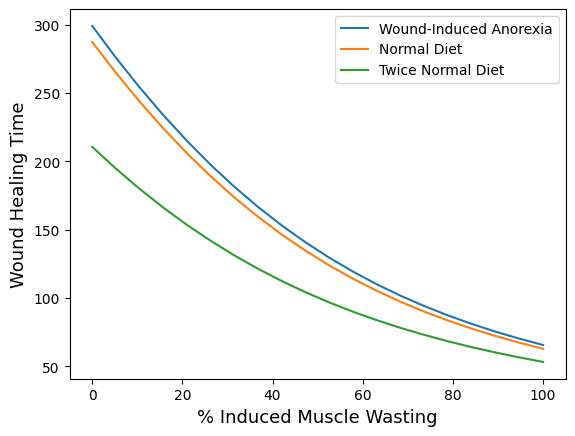

In [36]:
plt.plot([100 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], woundHealingTimeValues[0][:], label = "Wound-Induced Anorexia")
plt.plot([100 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], woundHealingTimeValues[1][:], label = "Normal Diet")
plt.plot([100 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], woundHealingTimeValues[2][:], label = "Twice Normal Diet")

#plt.title("Effect of Nutritional Support on Wound Healing", fontsize = 15)
plt.legend()

plt.xlabel("% Induced Muscle Wasting", fontsize = 13)
plt.ylabel("Wound Healing Time", fontsize = 13)

plt.savefig("FigureImages/Figure5Images/nutritionalSupportEffectOnWoundHealing.png")

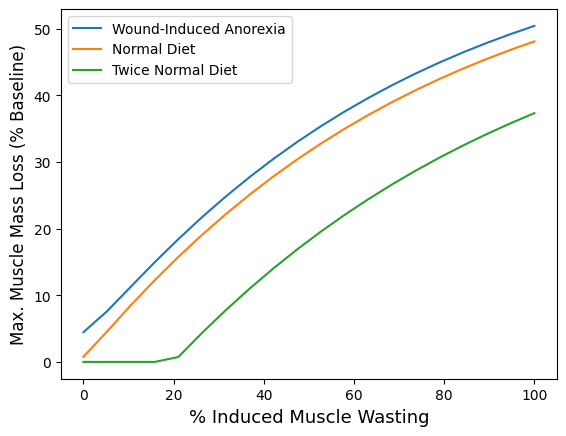

In [37]:
plt.plot([100 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], maxWeightDropVals[0][:] * 100, label = "Wound-Induced Anorexia")
plt.plot([100 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], maxWeightDropVals[1][:] * 100, label = "Normal Diet")
plt.plot([100 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], maxWeightDropVals[2][:] * 100, label = "Twice Normal Diet")

#plt.title("Effect of Nutritional Support on Maximum Acute Weight Loss", fontsize = 15)
plt.legend()

plt.xlabel("% Induced Muscle Wasting", fontsize = 13)
plt.ylabel("Max. Muscle Mass Loss (% Baseline)", fontsize = 12)

plt.savefig("FigureImages/Figure5Images/nutritionalSupportEffectOnAcuteMuscleMassLoss.png")

In [39]:
APREndpoints = np.zeros((2, 3, numPointsToTest))
pIEndpoints = np.zeros((2, 3, numPointsToTest))
phiEndpoints = np.zeros((2, 3, numPointsToTest))

cancerWeightEndpoints = np.zeros((2, 3, numPointsToTest))
cancerPopulationEndpoints = np.zeros((2, 3, numPointsToTest))

initialCancerPop = 0.0001

cancerN = 20

initWound = cancerN * initialCancerPop

cancerRxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_A', 'L_phi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'A', 'phi', 'pI', 'C'], components = {"Liver" : ['L_A', 'L_N','L_phi'], "Muscle" : ['M_full'], "Wound" : ['W', 'C'], "Soluble Mediators" : ['A', 'phi', 'pI'], "Diet" : ['D', 'D_phi']})

cancerRxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.5, 0, 100, 100, 0, 0, 1, 0, 0, initialCancerPop])

cancerRxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
cancerRxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
cancerRxnFlask.addReaction("Reaction 3: L_A + A -> L_N + A", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
cancerRxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
cancerRxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
cancerRxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#See Below for Reactions 7 and 8

#
cancerRxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
cancerRxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
cancerRxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
cancerRxnFlask.addReaction("Reaction 12: W -> W + phi", inflammationGenerationParam, reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
cancerRxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
cancerRxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
cancerRxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
cancerRxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
cancerRxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
cancerRxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
cancerRxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


#
cancerRxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
cancerRxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



#This allows M_full to continue acting as an inflammation sink while not changing state
cancerRxnFlask.addReaction("Reaction 7: M_full + phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})

#Note that the below reaction rate is 0: IMW is fully on
cancerRxnFlask.addReaction("Reaction 22: M_full + phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
cancerRxnFlask.addReaction("Reaction 8: M_empty + phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})

#Note that the below reaction rate is 0: IMW is fully on
cancerRxnFlask.addReaction("Reaction 23: M_empty + phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})


#The reactions governing replication
cancerRxnFlask.addReaction("Reaction 24: C + A -> C + C + nW", 0, reactantsDict = {'C' : 1, 'A' : 1}, productsDict = {'C' : 2, 'W' : cancerN})

#The reaction where cancer cells also produce inflammation
cancerRxnFlask.addReaction("Reaction 25: C -> C + phi", inflammationGenerationParam, reactantsDict = {'C' : 1}, productsDict = {'C' : 1, 'phi' : 1})

#The reactions governing cancer destruction
cancerRxnFlask.addReaction("Reaction 26: C + pI -> naught", 1, reactantsDict = {'C' : 1, 'pI' : 1}, productsDict = {})

for z in range(2):
    for j in range(3):
        for k in range(numPointsToTest):

            cancerGrowthRate = 0.01 * (k / (numPointsToTest - 1))
            
            if j in [0, 1]:
                diet = 1
            else:
                diet = 2

            woundValsVsTime = []

            
            cancerRxnFlask.modifyReaction("Reaction 24: C + A -> C + C + nW", newRxnRate=cancerGrowthRate, newRxnProductsDict={'C' : 2, 'W' : cancerN})
            

            if j == 0:
                #
                cancerRxnFlask.modifyReaction("Reaction 20: D + phi -> D_phi + phi", newRxnRate= 1)
    
                #
                cancerRxnFlask.modifyReaction("Reaction 21: D_phi -> D", newRxnRate= 0.1)
            else:
                #
                cancerRxnFlask.modifyReaction("Reaction 20: D + phi -> D_phi + phi", newRxnRate= 0)
                
                #
                cancerRxnFlask.modifyReaction("Reaction 21: D_phi -> D", newRxnRate= 0)


            if z == 0:
                #The reactions asserting NO induced muscle wasting

                #This allows M_full to continue acting as an inflammation sink while not changing state
                cancerRxnFlask.modifyReaction("Reaction 7: M_full + phi -> M_phi" , newRxnRate= 0)
                cancerRxnFlask.modifyReaction("Reaction 22: M_full + phi -> M_full" , newRxnRate= 1)

                #This allows M_empty to continue acting as an inflammation sink while not changing state
                cancerRxnFlask.modifyReaction("Reaction 8: M_empty + phi -> M_ePhi" , newRxnRate = 0)
                cancerRxnFlask.modifyReaction("Reaction 23: M_empty + phi -> M_empty" , newRxnRate= 1)

            else:
                #The reactions governing induced muscle wasting

                #This allows M_full to continue acting as an inflammation sink while not changing state
                cancerRxnFlask.modifyReaction("Reaction 7: M_full + phi -> M_phi" , newRxnRate= 1)
                cancerRxnFlask.modifyReaction("Reaction 22: M_full + phi -> M_full" , newRxnRate= 0)

                #This allows M_empty to continue acting as an inflammation sink while not changing state
                cancerRxnFlask.modifyReaction("Reaction 8: M_empty + phi -> M_ePhi" , newRxnRate = 1)
                cancerRxnFlask.modifyReaction("Reaction 23: M_empty + phi -> M_empty" , newRxnRate= 0)



            cancerRxnFlask.resetInitialCondition()
            cancerRxnFlask.runSystem(1000)

            #cancerRxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)
            
            aprEndpoint = cancerRxnFlask.getFinalValueOfSpecies('L_phi')
            pIEndpoint = cancerRxnFlask.getFinalValueOfSpecies('pI')
            phiEndpoint = cancerRxnFlask.getFinalValueOfSpecies('phi')

            cancerEndpoint = cancerRxnFlask.getFinalValueOfSpecies('C')
            weightEndpoint = cancerRxnFlask.getFinalValueOfSpecies('M_full')
            
            APREndpoints[z][j][k] = aprEndpoint
            pIEndpoints[z][j][k] = pIEndpoint
            phiEndpoints[z][j][k] = phiEndpoint

            cancerPopulationEndpoints[z][j][k] = cancerEndpoint
            cancerWeightEndpoints[z][j][k] = weightEndpoint

            print(f"Finished {z * 3 * numPointsToTest + j * numPointsToTest + k + 1} iterations out of {2 * 3 * numPointsToTest}")



Finished 1 iterations out of 120
Finished 2 iterations out of 120
Finished 3 iterations out of 120
Finished 4 iterations out of 120
Finished 5 iterations out of 120
Finished 6 iterations out of 120
Finished 7 iterations out of 120
Finished 8 iterations out of 120
Finished 9 iterations out of 120
Finished 10 iterations out of 120
Finished 11 iterations out of 120
Finished 12 iterations out of 120
Finished 13 iterations out of 120
Finished 14 iterations out of 120
Finished 15 iterations out of 120
Finished 16 iterations out of 120
Finished 17 iterations out of 120
Finished 18 iterations out of 120
Finished 19 iterations out of 120
Finished 20 iterations out of 120
Finished 21 iterations out of 120
Finished 22 iterations out of 120
Finished 23 iterations out of 120
Finished 24 iterations out of 120
Finished 25 iterations out of 120
Finished 26 iterations out of 120
Finished 27 iterations out of 120
Finished 28 iterations out of 120
Finished 29 iterations out of 120
Finished 30 iterations 

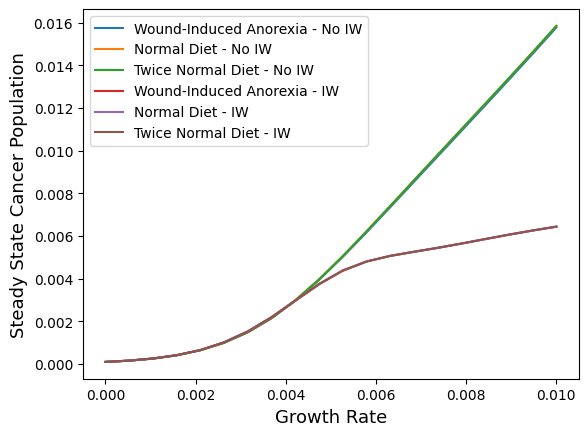

In [40]:
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerPopulationEndpoints[0][0][:], label = "Wound-Induced Anorexia - No IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerPopulationEndpoints[0][1][:], label = "Normal Diet - No IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerPopulationEndpoints[0][2][:], label = "Twice Normal Diet - No IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerPopulationEndpoints[1][0][:], label = "Wound-Induced Anorexia - IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerPopulationEndpoints[1][1][:], label = "Normal Diet - IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerPopulationEndpoints[1][2][:], label = "Twice Normal Diet - IW")

#Move legend to lower left-hand corner
plt.legend()

plt.xlabel("Growth Rate", fontsize = 13)
plt.ylabel("Steady State Cancer Population", fontsize = 13)

plt.savefig("FigureImages/Figure5Images/nutritionalSupportEffectOnSteadStateCancerPopSize.png")

[99.9818346  99.9704079  99.95221703 99.92379368 99.88051389 99.81685137
 99.7272587  99.60771808 99.4574414  99.27969347 99.08100023 98.86911174
 98.6509217  98.43129162 98.2128969  97.9966778  97.78244746 97.56940683
 97.35649487 97.14259269]


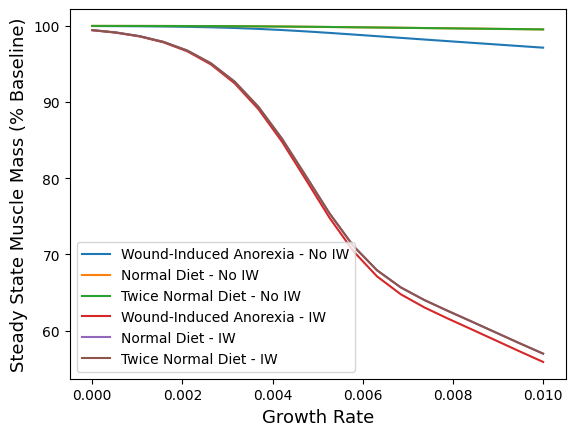

In [41]:
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerWeightEndpoints[0][0][:], label = "Wound-Induced Anorexia - No IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerWeightEndpoints[0][1][:], label = "Normal Diet - No IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerWeightEndpoints[0][2][:], label = "Twice Normal Diet - No IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerWeightEndpoints[1][0][:], label = "Wound-Induced Anorexia - IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerWeightEndpoints[1][1][:], label = "Normal Diet - IW")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerWeightEndpoints[1][2][:], label = "Twice Normal Diet - IW")

print(cancerWeightEndpoints[0][0][:])
#Move legend to lower left-hand corner
plt.legend(loc = 'lower left')

plt.xlabel("Growth Rate", fontsize = 13)
plt.ylabel("Steady State Muscle Mass (% Baseline)", fontsize = 13)

plt.savefig("FigureImages/Figure5Images/nutritionalSupportEffectOnSteadyStateWeightCancer.png")

7.76952791237776e-05


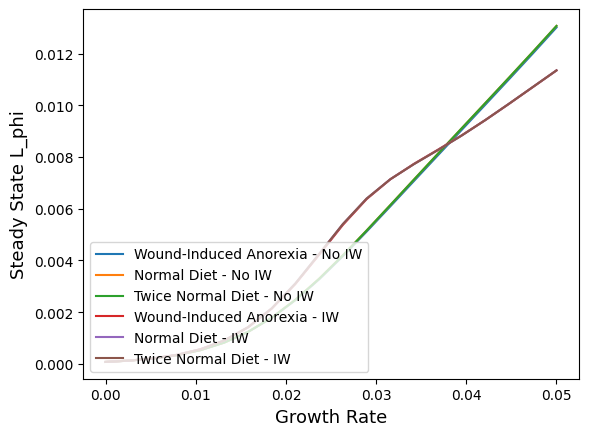

In [ ]:
plt.plot([0.05 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], APREndpoints[0][0][:], label = "Wound-Induced Anorexia - No IW")
plt.plot([0.05 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], APREndpoints[0][1][:], label = "Normal Diet - No IW")
plt.plot([0.05 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], APREndpoints[0][2][:], label = "Twice Normal Diet - No IW")
plt.plot([0.05 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], APREndpoints[1][0][:], label = "Wound-Induced Anorexia - IW")
plt.plot([0.05 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], APREndpoints[1][1][:], label = "Normal Diet - IW")
plt.plot([0.05 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], APREndpoints[1][2][:], label = "Twice Normal Diet - IW")


#Move legend to lower left-hand corner
plt.legend(loc = 'lower left')

plt.xlabel("Growth Rate", fontsize = 13)
plt.ylabel("Steady State L_phi", fontsize = 13)

plt.savefig("FigureImages/Figure5Images/nutritionalSupportEffectOnInflamedLiverAPR.png")